# Week 2: DreamBooth-LoRA vs. IP-Adapter

Trains a LoRA on one pet, then generates the same prompts three ways and scores them:

| method | how the pet gets in | per-pet cost |
|---|---|---|
| `text_only` | it doesn't (baseline) | none |
| `ip_adapter` | photo encoded at request time | none |
| `lora` | DreamBooth-LoRA trained on the photos | one training run |

The scores are **DINO** and **CLIP-I** (does it look like *this* pet), **CLIP-T** (does it follow the prompt), and latency.

**Setup:** use a T4 GPU and a **fresh session**. Upload `common.py`, `handler.py`, `train.py`, `requirements.txt` and `eval/identity.py` (as `identity.py`) to `/content`. Put 3–10 photos of the pet in `/content/pet_photos/`. More photos with varied angles give a better LoRA.

In [1]:
!nvidia-smi --query-gpu=name,memory.used --format=csv
!pip install -q -r requirements.txt pandas

name, memory.used [MiB]
Tesla T4, 0 MiB


## 1. Train the LoRA
Runs in a subprocess, so the GPU is free again afterwards. On a T4 at 768px, expect roughly 15–30 min for 500 steps. That number is the baseline for time-to-first-image.

In [2]:
import base64, glob, json, os, time
os.environ['LOW_VRAM'] = '1'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

photos = sorted(glob.glob('/content/pet_photos/*'))
print(len(photos), 'photos')
images_b64 = [base64.b64encode(open(p, 'rb').read()).decode() for p in photos]

import train
CLASS = 'cat'  # or 'dog'
TRAIN_CFG = {'images': images_b64, 'class_word': CLASS, 'steps': 500, 'rank': 8,
             'learning_rate': 1e-4, 'resolution': 768, 'run_id': 'pet-v1'}
t0 = time.perf_counter()
train_out = train.train(TRAIN_CFG)
if 'error' in train_out:
    print(train_out.get('log_tail', '')); raise RuntimeError(train_out['error'])
print(json.dumps({k: v for k, v in train_out.items()}, indent=1, default=str))

3 photos
[train] 3 photos, 'a photo of sks cat', 768px, 500 steps, rank 8
[train]   25/500 (  5%)  2.12 s/it  loss 0.3390  elapsed 00:55  eta 16:49
[train]   50/500 ( 10%)  2.35 s/it  loss 0.0547  elapsed 01:50  eta 17:37
[train]   75/500 ( 15%)  2.22 s/it  loss 0.0022  elapsed 02:47  eta 15:41
[train]  100/500 ( 20%)  2.32 s/it  loss 0.0312  elapsed 03:43  eta 15:27
[train]  125/500 ( 25%)  2.21 s/it  loss 0.3440  elapsed 04:38  eta 13:49
[train]  150/500 ( 30%)  2.24 s/it  loss 0.3180  elapsed 05:34  eta 13:03
[train]  175/500 ( 35%)  2.23 s/it  loss 0.0461  elapsed 06:30  eta 12:04
[train]  200/500 ( 40%)  2.21 s/it  loss 0.0290  elapsed 07:26  eta 11:03
[train]  225/500 ( 45%)  2.27 s/it  loss 0.0411  elapsed 08:22  eta 10:23
[train]  250/500 ( 50%)  2.21 s/it  loss 0.2700  elapsed 09:17  eta 09:11
[train]  275/500 ( 55%)  2.22 s/it  loss 0.3430  elapsed 10:13  eta 08:18
[train]  300/500 ( 60%)  2.22 s/it  loss 0.0036  elapsed 11:09  eta 07:23
[train]  325/500 ( 65%)  2.19 s/it  lo

## 2. Generate the comparison set
The same prompts and seeds for every method. The generation model loads into this notebook now, which is fine because training is done.

In [4]:
import handler, io
from PIL import Image

SCENES = ['as a pirate captain on a ship, wearing a tricorn hat, funny, cinematic',
          'as an astronaut on the moon, wearing a space helmet, cinematic',
          'as a chef in a busy kitchen, wearing a chef hat, funny',
          'sitting on a throne like a king, wearing a crown, oil painting']
SEEDS = [1, 2]
GEN = {'width': 768, 'height': 768, 'steps': 25}
TOKEN_SUBJECT = train_out['instance_prompt'].replace('a photo of ', '')  # e.g. 'sks cat'

METHODS = {
    'text_only':  lambda s: {'prompt': f'a {CLASS} {s}'},
    'ip_adapter': lambda s: {'prompt': f'a {CLASS} {s}', 'pet_image': images_b64[0], 'ip_adapter_scale': 0.6},
    'lora':       lambda s: {'prompt': f'a {TOKEN_SUBJECT} {s}', 'lora': train_out['lora_path'], 'lora_scale': 0.9},
}

os.makedirs('results', exist_ok=True)
rows, first_lora_ms = [], None
for method, build in METHODS.items():
    for i, scene in enumerate(SCENES):
        for seed in SEEDS:
            inp = {**build(scene), **GEN, 'seed': seed}
            t = time.perf_counter()
            out = handler.handler({'input': inp})
            wall = (time.perf_counter() - t) * 1000
            if method == 'lora' and first_lora_ms is None:
                first_lora_ms = wall
            path = f'results/{method}_{i}_{seed}.png'
            open(path, 'wb').write(base64.b64decode(out['image_base64']))
            rows.append({'method': method, 'scene': i, 'seed': seed, 'prompt': f'a {CLASS} {scene}',
                         'path': path, 'latency_ms': wall, **{f't_{k}': v for k, v in out['timings_ms'].items()}})
        print(method, 'scene', i, 'done')

ttfi = (train_out['timings_ms']['total'] + first_lora_ms) / 60000
print(f'time-to-first-image (LoRA): {ttfi:.1f} min')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

unet/diffusion_pytorch_model.fp16.safete(…):   0%|          | 0.00/5.14G [00:00<?, ?B/s]

text_encoder/model.fp16.safetensors:   0%|          | 0.00/246M [00:00<?, ?B/s]

text_encoder_2/model.fp16.safetensors:   0%|          | 0.00/1.39G [00:00<?, ?B/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

lora scene 2 done


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

lora scene 3 done
time-to-first-image (LoRA): 21.3 min


## 3. Score
Free the generation model, then load DINOv2 and CLIP. CLIP-T is scored against the prompt *without* the `sks` token, so all three methods are judged on the same text.

In [5]:
import gc, torch, pandas as pd
del handler.pipe; gc.collect(); torch.cuda.empty_cache()

from identity import IdentityScorer
scorer = IdentityScorer()
scorer.set_references([Image.open(p).convert('RGB') for p in photos])
for r in rows:
    r.update(scorer.score(Image.open(r['path']).convert('RGB'), r['prompt']))

df = pd.DataFrame(rows)
df.to_csv('results/results.csv', index=False)
summary = df.groupby('method')[['dino', 'clip_i', 'clip_t', 'latency_ms', 't_inference']].mean().round(3)
summary.loc['lora', 'per_pet_train_min'] = round(train_out['timings_ms']['total'] / 60000, 1)
summary

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

,dino,clip_i,clip_t,latency_ms,t_inference,per_pet_train_min
method,,,,,,
ip_adapter,0.663,0.727,0.271,14561.288,14269.650,NaN
lora,0.631,0.665,0.317,15456.848,14860.599,21.1
text_only,0.038,0.620,0.317,13603.522,13308.854,NaN


## 4. Look at them
Numbers can lie (for example, a high DINO score from copying the photo's background), so check the grid too.

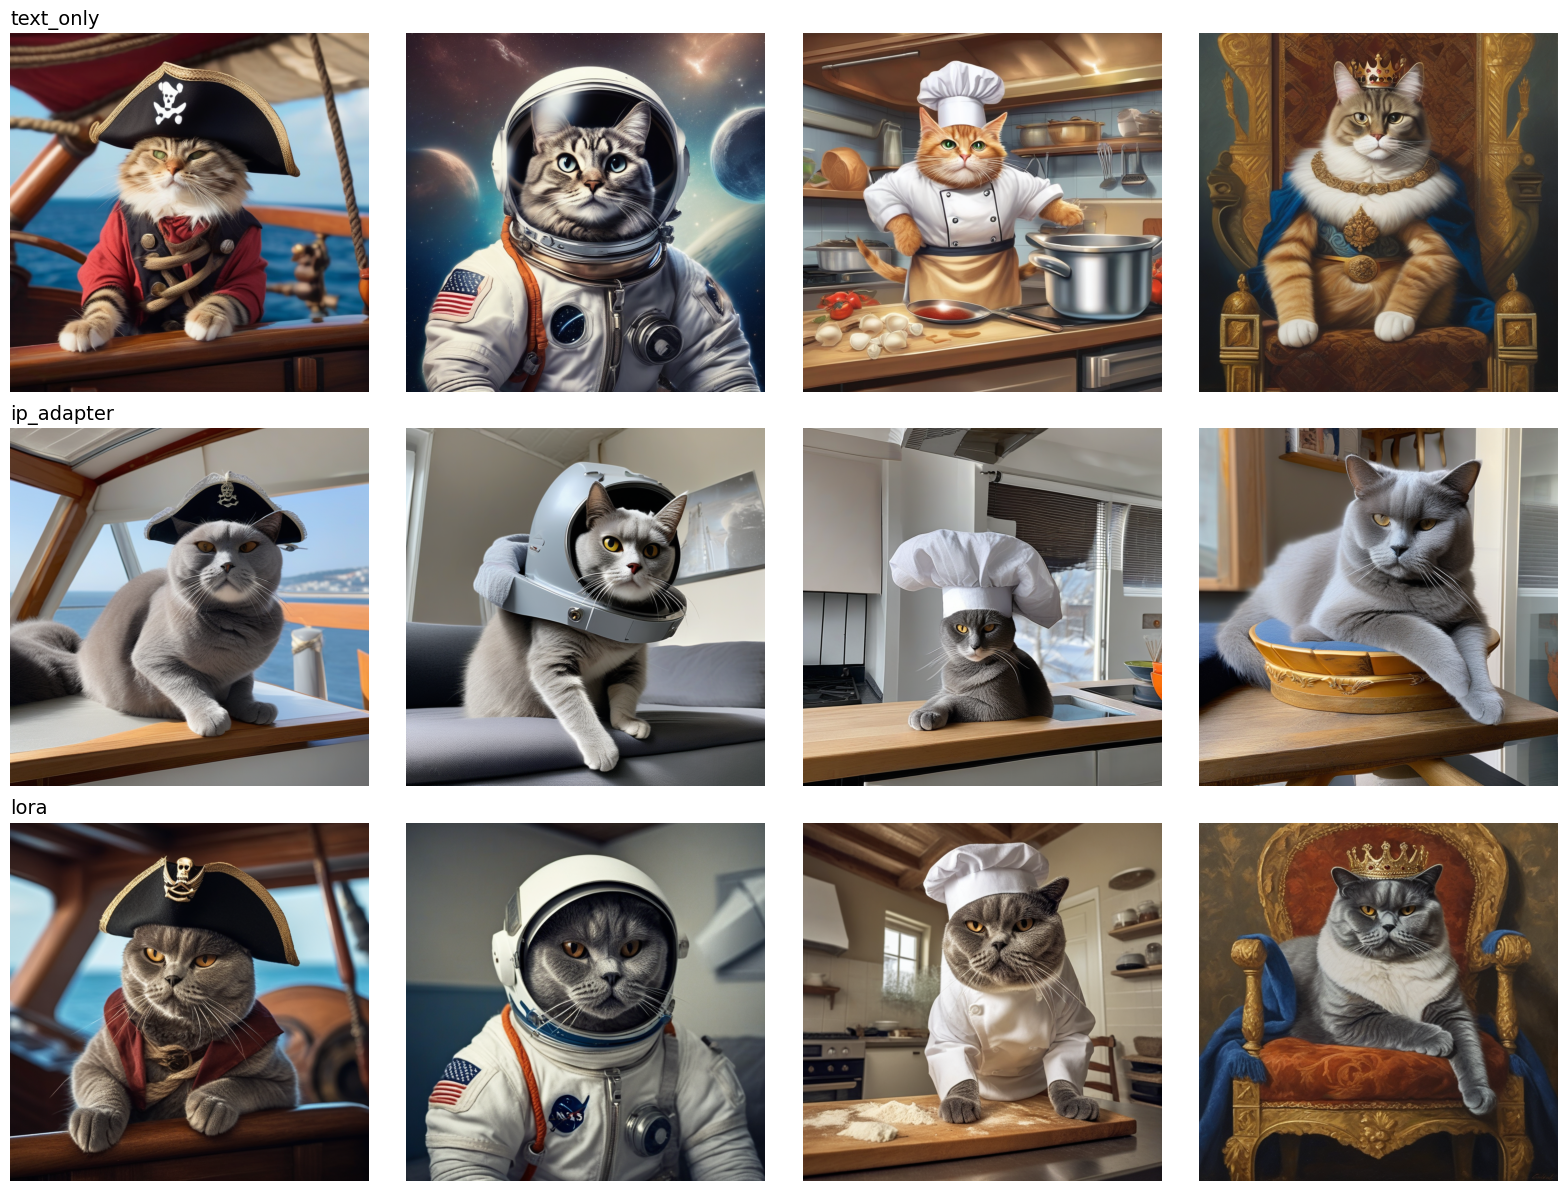

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(len(METHODS), len(SCENES), figsize=(4 * len(SCENES), 4 * len(METHODS)))
for r, method in enumerate(METHODS):
    for c in range(len(SCENES)):
        axes[r, c].imshow(Image.open(f'results/{method}_{c}_{SEEDS[0]}.png')); axes[r, c].axis('off')
        if c == 0: axes[r, c].set_title(method, loc='left', fontsize=14)
plt.tight_layout(); plt.savefig('results/grid.png', dpi=80); plt.show()

In [7]:
# Download everything (images, results.csv, grid.png and the LoRA)
!cp {train_out['lora_path']} results/
!zip -qr results.zip results
from google.colab import files; files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>